# IMPORT ALL NECCESARY LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings("ignore")

# GENERATE DATASET

In [2]:
data_frame = pd.read_csv(r"C:\Users\Admin\OneDrive\Documents\Data Science Project\corporate_clients_dataset-.csv")

# UNDERSTANDING THE DATASET

### THE HEAD

In [3]:
data_frame.head()

,ClientID,PlacementFee_ZAR,DaysPastDue,ClientIndustry,CompanySize,HistoricalDefaultScore,DefaultStatus
0,1001,20795,157,Tech,Mid-Market,0.04,1
1,1002,5860,47,Retail,SMME,0.98,1
2,1003,81820,34,Retail,Mid-Market,0.45,0
3,1004,59886,85,Manufacturing,SMME,0.36,0
4,1005,11265,165,Manufacturing,Mid-Market,0.29,1


### THE TAIL

In [4]:
data_frame.tail()

,ClientID,PlacementFee_ZAR,DaysPastDue,ClientIndustry,CompanySize,HistoricalDefaultScore,DefaultStatus
4995,5996,68344,32,Retail,SMME,0.57,0
4996,5997,40618,144,Manufacturing,SMME,0.43,1
4997,5998,81234,151,Finance,SMME,0.02,1
4998,5999,66114,157,Manufacturing,Enterprise,0.24,1
4999,6000,75130,140,Tech,SMME,0.28,1


### DATASET INFORMATION

In [5]:
data_frame.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ClientID                5000 non-null   int64  
 1   PlacementFee_ZAR        5000 non-null   int64  
 2   DaysPastDue             5000 non-null   int64  
 3   ClientIndustry          4950 non-null   str    
 4   CompanySize             5000 non-null   str    
 5   HistoricalDefaultScore  5000 non-null   float64
 6   DefaultStatus           5000 non-null   int64  
dtypes: float64(1), int64(4), str(2)
memory usage: 273.6 KB


### DATASET SHAPE

In [6]:
data_frame.shape

(5000, 7)

### DATASET DESCRIPTION

In [7]:
data_frame.describe()

,ClientID,PlacementFee_ZAR,DaysPastDue,HistoricalDefaultScore,DefaultStatus
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,3500.500000,51281.952000,92.487400,0.502324,0.65220
std,1443.520003,29427.569571,60.273948,0.289371,0.47632
min,1001.000000,-94881.000000,-20.000000,0.000000,0.00000
25%,2250.750000,27863.250000,45.000000,0.250000,0.00000
50%,3500.500000,51408.000000,91.000000,0.510000,1.00000
75%,4750.250000,76298.250000,136.000000,0.752500,1.00000
max,6000.000000,99986.000000,500.000000,1.000000,1.00000


### CHECKING FOR MISSING VALUES

In [8]:
data_frame.isnull().sum()

ClientID                   0
PlacementFee_ZAR           0
DaysPastDue                0
ClientIndustry            50
CompanySize                0
HistoricalDefaultScore     0
DefaultStatus              0
dtype: int64

### CHECKING FOR MISSING VALUES PERCENTAGE

In [9]:
data_frame.isnull().sum()/data_frame.shape[0]*100

ClientID                  0.0
PlacementFee_ZAR          0.0
DaysPastDue               0.0
ClientIndustry            1.0
CompanySize               0.0
HistoricalDefaultScore    0.0
DefaultStatus             0.0
dtype: float64

###  CHECKING FOR DUPLICATES

In [10]:
data_frame.duplicated().sum()

np.int64(0)

### CHECKING FOR NEGATIVE PLACEMENTFEE

In [11]:
(data_frame["PlacementFee_ZAR"] < 0).sum()

np.int64(50)

### CHECKING FOR IMPOSSIBLE DAYS PAST DUE

In [12]:
data_frame[(data_frame["DaysPastDue"] < 0) | (data_frame["DaysPastDue"] > 365)]

,ClientID,PlacementFee_ZAR,DaysPastDue,ClientIndustry,CompanySize,HistoricalDefaultScore,DefaultStatus
40,1041,8890,500,Finance,Enterprise,0.76,1
64,1065,57995,-20,Retail,Enterprise,0.23,0
70,1071,70697,500,Finance,Mid-Market,0.80,1
273,1274,48016,500,Manufacturing,Enterprise,0.28,1
305,1306,96412,500,Manufacturing,Enterprise,0.36,0
487,1488,96747,-20,Finance,SMME,0.60,1
708,1709,57736,500,Tech,SMME,0.71,1
808,1809,99074,-20,Retail,SMME,0.46,1
1031,2032,13512,-20,Tech,SMME,0.49,0
1045,2046,72444,500,Finance,Enterprise,0.14,1


# HANDLING THE MISSING VALUES

### HANDLING THE MISSING VALUES

In [13]:
mode_industry = data_frame["ClientIndustry"].mode()[0]
data_frame["ClientIndustry"] = data_frame["ClientIndustry"].fillna(mode_industry)

### FIX NEGATIVE PLACEMENT FEES

In [14]:
data_frame["PlacementFee_ZAR"] = data_frame["PlacementFee_ZAR"].abs()

### FIX IMPOSSABLE DAYSPASTDUE VALUES

In [15]:
data_frame.loc[data_frame["DaysPastDue"] < 0, "DaysPastDue"] = 0
data_frame.loc[data_frame["DaysPastDue"] > 365, "DaysPastDue"] = 365


# CATEGORICAL ENCODING

### ONE-HOT ENCODING

In [16]:
data_frame = pd.get_dummies(
    data_frame,
    columns=["ClientIndustry", "CompanySize"],
    drop_first=True
)

# FEATURE ENGINEERING

### RISK EXPOSURE LEVEL

In [17]:
data_frame["RiskExposureLevel"] = (
    data_frame["PlacementFee_ZAR"]
    * (1 + data_frame["HistoricalDefaultScore"])
    * (1 + data_frame["DaysPastDue"] / 365)
)

### CORRELATION HEATMAP

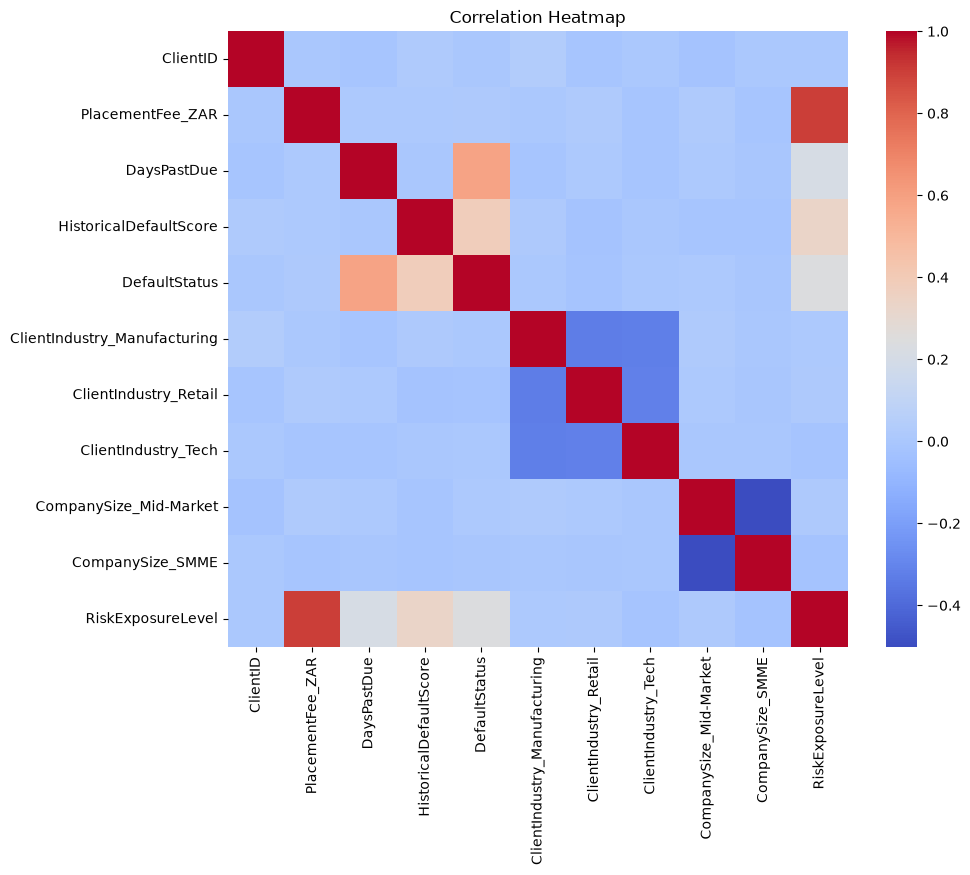

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(data_frame.corr(), annot=False, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.savefig("CorrelationHeatmap.png")
plt.show()

### BOXPLOT

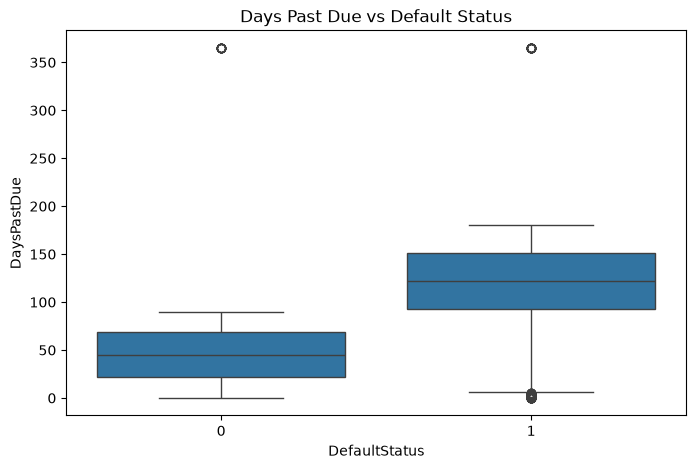

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="DefaultStatus",
    y="DaysPastDue",
    data=data_frame
)

plt.title("Days Past Due vs Default Status")
plt.savefig("DaysPastDue_vs_Default.png")
plt.show()

In [20]:
data_frame.corr(numeric_only=True)["DefaultStatus"].sort_values(ascending=False)

DefaultStatus                   1.000000
DaysPastDue                     0.588297
HistoricalDefaultScore          0.379217
RiskExposureLevel               0.242904
PlacementFee_ZAR                0.014803
CompanySize_Mid-Market          0.009879
ClientIndustry_Manufacturing    0.007253
ClientIndustry_Tech             0.006564
ClientID                        0.000565
CompanySize_SMME               -0.005745
ClientIndustry_Retail          -0.017351
Name: DefaultStatus, dtype: float64

# CHECKING THE REMAINING DATASET

### DATASET INFORMATION

In [21]:
data_frame.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ClientID                      5000 non-null   int64  
 1   PlacementFee_ZAR              5000 non-null   int64  
 2   DaysPastDue                   5000 non-null   int64  
 3   HistoricalDefaultScore        5000 non-null   float64
 4   DefaultStatus                 5000 non-null   int64  
 5   ClientIndustry_Manufacturing  5000 non-null   bool   
 6   ClientIndustry_Retail         5000 non-null   bool   
 7   ClientIndustry_Tech           5000 non-null   bool   
 8   CompanySize_Mid-Market        5000 non-null   bool   
 9   CompanySize_SMME              5000 non-null   bool   
 10  RiskExposureLevel             5000 non-null   float64
dtypes: bool(5), float64(2), int64(4)
memory usage: 258.9 KB


In [22]:
data_frame.isnull().sum()

ClientID                        0
PlacementFee_ZAR                0
DaysPastDue                     0
HistoricalDefaultScore          0
DefaultStatus                   0
ClientIndustry_Manufacturing    0
ClientIndustry_Retail           0
ClientIndustry_Tech             0
CompanySize_Mid-Market          0
CompanySize_SMME                0
RiskExposureLevel               0
dtype: int64

### REMOVE CLIENT ID

In [23]:
data_frame = data_frame.drop("ClientID", axis=1)


`ClientID` was removed because it is simply an identifier and does not provide meaningful information for predicting default.

In [24]:
data_frame["DefaultStatus"].value_counts()

DefaultStatus
1    3261
0    1739
Name: count, dtype: int64

# SPLIT FEATURES AND TARGET

In [25]:
X = data_frame.drop("DefaultStatus", axis=1)
y = data_frame["DefaultStatus"]


# TRAIN TEST SPLIT

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# LOGISTIC REGRASSION MODEL

In [27]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [28]:
y_pred_lr = lr.predict(X_test)

In [29]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84       348
           1       0.91      0.93      0.92       652

    accuracy                           0.90      1000
   macro avg       0.89      0.88      0.88      1000
weighted avg       0.89      0.90      0.89      1000



### CONFUSION MATRIX

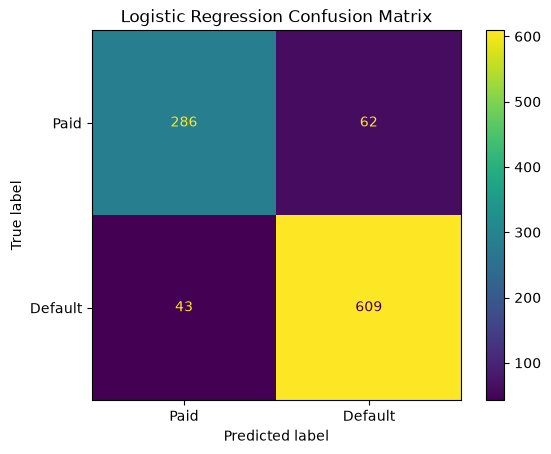

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Paid", "Default"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.savefig("LogisticRegression_ConfusionMatrix.png")
plt.show()

True Paid → Predicted Paid: 286

True Paid → Predicted Default: 62 (false negatives)

True Default → Predicted Paid: 43 (false positives)

True Default → Predicted Default: 609

# RANDOM FOREST CLASSIFIER MODEL

In [31]:
rf = RandomForestClassifier(
    random_state=42
)

rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [32]:
y_pred_rf = rf.predict(X_test)

In [33]:
print(classification_report(
    y_test,
    y_pred_rf
))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       348
           1       1.00      1.00      1.00       652

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



### CONFUSION MATRIX

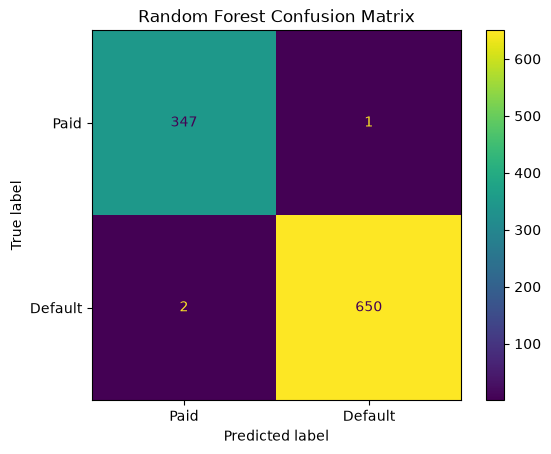

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Paid", "Default"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.savefig("RandomForest_ConfusionMatrix.png")
plt.show()

True Paid → Predicted Paid: 347

True Paid → Predicted Default: 1 (almost no false negatives)

True Default → Predicted Paid: 2 (almost no false positives)

True Default → Predicted Default: 650

## COMPORISON

### CLASSIFICATION REPORT

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall
0  Logistic Regression     0.895   0.907601  0.934049
1        Random Forest     0.997   0.998464  0.996933


### CONFUSION MATRIX

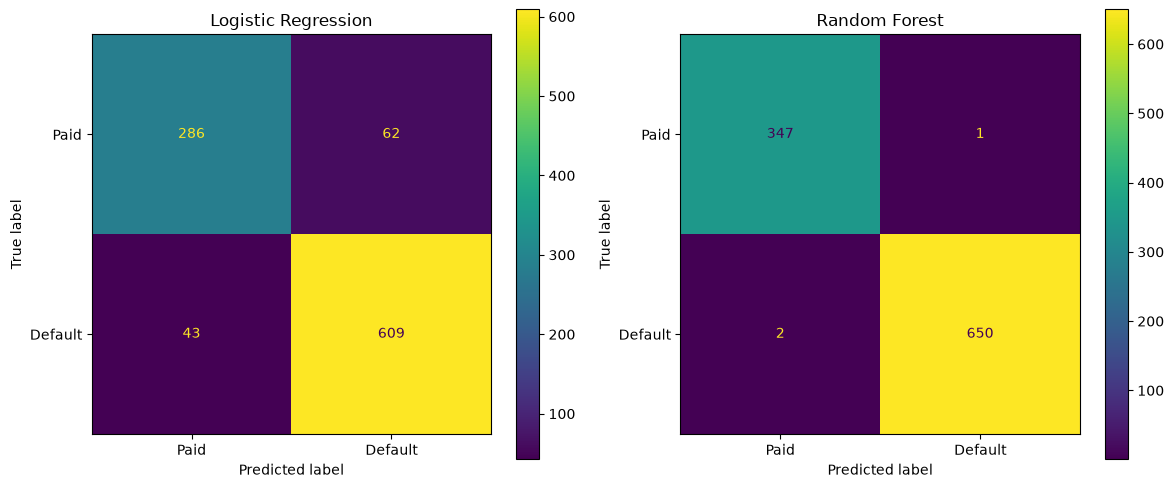

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Paid", "Default"]
).plot(ax=axes[0])

axes[0].set_title("Logistic Regression")

# Random Forest
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Paid", "Default"]
).plot(ax=axes[1])

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.savefig("Model_Confusion_Matrix_Comparison.png")
plt.show()

# FEATURE IMPORTANCE

In [37]:
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(ascending=False)

print(importance)

DaysPastDue                     0.606618
HistoricalDefaultScore          0.335070
RiskExposureLevel               0.039963
PlacementFee_ZAR                0.014992
ClientIndustry_Tech             0.000909
CompanySize_Mid-Market          0.000742
CompanySize_SMME                0.000729
ClientIndustry_Retail           0.000584
ClientIndustry_Manufacturing    0.000393
dtype: float64


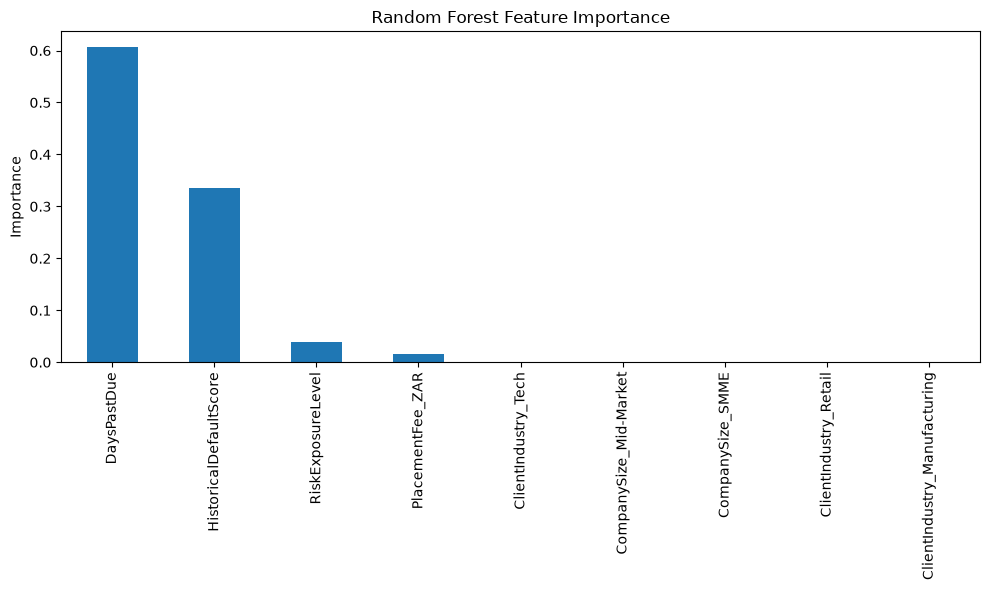

In [38]:
plt.figure(figsize=(10,6))

importance.plot(kind="bar")

plt.title("Random Forest Feature Importance")

plt.ylabel("Importance")

plt.tight_layout()

plt.savefig("FeatureImportance.png")

plt.show()

### CROSS VALIDATION

In [39]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

CV Scores: [0.997 0.997 0.995 0.997 0.994]
Mean CV Accuracy: 0.9959999999999999


### SAVED THE BEST MODEL

In [40]:
import joblib

joblib.dump(rf, "random_forest_default_model.pkl")

['random_forest_default_model.pkl']

# Summary Report

## 1. Project Overview

The purpose of this project is to develop a machine learning system that predicts whether a corporate client is likely to **default or pay on time**.

The target variable was **DefaultStatus**, where:

* `0` = Paid on Time
* `1` = Defaulted/Severely Delayed

---

## 2. Dataset Description

The original dataset contained **5,000 rows and 7 columns**.

| Variable               | Description                                |
| ---------------------- | ------------------------------------------ |
| ClientID               | Unique identifier for each client          |
| PlacementFee_ZAR       | Client placement fee in South African Rand |
| DaysPastDue            | Number of days a payment is overdue        |
| ClientIndustry         | Client's industry                          |
| CompanySize            | Size of the company                        |
| HistoricalDefaultScore | Historical measure of default risk         |
| DefaultStatus          | Target variable indicating default         |

The dataset contained:

* **5,000 records**
* **7 original variables**
* **50 missing ClientIndustry values**
* **No duplicate records**
* Negative PlacementFee values
* Invalid DaysPastDue values

---

## 3. Data Exploration

The `head()`, `tail()` `info()`, `shape()`, and `describe()` functions were used to understand the structure and distribution of the dataset.

The dataset had 5,000 records, with the following important observations:

* Average Placement Fee: approximately **R51,282**
* Average Days Past Due: approximately **92 days**
* Average Historical Default Score: approximately **0.50**
* Defaulted clients: **3,261**
* Paid-on-time clients: **1,739**

This means approximately **65.2% of the clients were classified as defaulted**, while approximately **34.8% paid on time**.

---

## 4. Data Cleaning

Several data quality problems were identified and corrected.

### Missing Values

There were **50 missing values** in `ClientIndustry`, representing **1% of the dataset**.

The missing values were replaced using the **mode** of the ClientIndustry column.

### Negative Placement Fees

Negative values were identified in `PlacementFee_ZAR`.

Since a placement fee cannot logically be negative, the values were converted to positive values using:

`abs()`

### Invalid Days Past Due

Some `DaysPastDue` values were outside the logical range.

The project applied the following rules:

* Values below `0` were changed to `0`
* Values above `365` were changed to `365`

This ensured that the Days Past Due variable contained reasonable values.

### Duplicate Records

The dataset contained **no duplicate records**, so no rows had to be removed.

---

## 5. Feature Encoding

The categorical variables:

* ClientIndustry
* CompanySize

were converted into numerical variables using **one-hot encoding** with `pd.get_dummies()`.

The `drop_first=True` option was used to avoid unnecessary redundant categories.

After encoding, the dataset contained **11 columns**.

---

## 6. Feature Engineering

A new variable called **RiskExposureLevel** was created.

The formula was:

`PlacementFee_ZAR × (1 + HistoricalDefaultScore) × (1 + DaysPastDue / 365)`

This feature combines three important risk factors:

* Financial exposure
* Historical default risk
* Payment delay

The purpose was to create a combined measure that could help the machine learning models identify clients with higher default risk.

---

## 7. Exploratory Data Analysis

Two main visualizations were created.

### Correlation Heatmap

A correlation heatmap was created to examine relationships between numerical variables and identify potentially important relationships within the dataset.

### Days Past Due vs Default Status

A boxplot was created to compare **DaysPastDue** between clients who paid on time and clients who defaulted.

This visualization helps determine whether payment delays are associated with default status.

---

## 8. Preparing the Machine Learning Data

`ClientID` was removed because it is simply an identifier and does not provide meaningful information for predicting default.

The dataset was divided into:

* **Features (X):** predictor variables
* **Target (y):** DefaultStatus

The data was split into:

* **80% training data**
* **20% testing data**

A `random_state=42` was used to make the results reproducible.

`stratify=y` was also used to maintain the proportion of default and non-default clients in both the training and testing datasets.

---

# 9. Logistic Regression Model

The first machine learning model was **Logistic Regression**.

The model achieved:

| Metric    |                                  Result |
| --------- | --------------------------------------: |
| Accuracy  |                               **89.5%** |
| Precision |                               **90.8%** |
| Recall    |                               **93.4%** |
| F1-score  | **Approximately 92% for Default class** |

The model performed well and was able to correctly identify a large proportion of clients who defaulted.

The recall of **93.4%** is particularly useful because identifying clients who are likely to default is an important objective of this project.

---

# 10. Random Forest Model

The second model was a **Random Forest Classifier**.

The Random Forest produced significantly stronger results:

| Metric    |     Result |
| --------- | ---------: |
| Accuracy  |  **99.7%** |
| Precision | **99.85%** |
| Recall    | **99.69%** |

These results indicate that the Random Forest classified almost all clients correctly on the test dataset.

---

# 11. Model Comparison

The two models were compared using Accuracy, Precision and Recall.

| Model               |  Accuracy |  Precision |     Recall |
| ------------------- | --------: | ---------: | ---------: |
| Logistic Regression |     89.5% |     90.76% |     93.40% |
| Random Forest       | **99.7%** | **99.85%** | **99.69%** |

### Interpretation

The Random Forest performed considerably better than Logistic Regression across all three evaluation metrics.

The Random Forest achieved:

* **10.2 percentage points higher accuracy**
* **9.1 percentage points higher precision**
* **6.3 percentage points higher recall**

Therefore, based on the current test results, **Random Forest is the better-performing model for this dataset**.

---

# 12. Confusion Matrix

Confusion matrices were created for both models.

A confusion matrix shows:

* **True Positive (TP):** Correctly predicted default
* **True Negative (TN):** Correctly predicted paid-on-time
* **False Positive (FP):** Predicted default when the client paid
* **False Negative (FN):** Predicted paid when the client defaulted

The confusion matrices provide a more detailed view of how each model classified the test clients.

The Random Forest confusion matrix is expected to show very few incorrect predictions because of its **99.7% accuracy**.

---

# 13. Random Forest Feature Importance

Feature importance was calculated using the Random Forest model.

This analysis helps identify which variables contributed most to the model's predictions.

The feature importance chart allows the business to understand which factors are most useful when predicting client default.

The most important variables should be examined carefully because they can provide useful business insights into the characteristics associated with client default.

---

# 14. Key Findings

The project produced several important findings:

1. The dataset contained **5,000 corporate client records**.
2. The data contained missing values and synthetic anomalies that required cleaning.
3. Missing ClientIndustry values were successfully imputed using the mode.
4. Negative placement fees were corrected.
5. Invalid DaysPastDue values were restricted to a logical range of 0–365 days.
6. Categorical variables were successfully converted into numerical features.
7. A new RiskExposureLevel feature was created to combine financial and credit-risk information.
8. Logistic Regression achieved **89.5% accuracy**.
9. Random Forest achieved **99.7% accuracy**.
10. Random Forest performed better than Logistic Regression on the test dataset.

---

# 15. Conclusion

Based on the findings, I recommend that the business implement an early-warning credit-risk system. Clients with increasing DaysPastDue, high HistoricalDefaultScore, or high predicted default risk should be flagged for early intervention. The business can then contact the client, review their credit limit, negotiate a payment arrangement, or restrict further credit exposure.

The machine learning model should be used as a decision-support tool to help the credit and collections teams identify potentially risky clients earlier. This could help the business reduce financial losses and improve debt collection.